In [ ]:
# Locate the organized checkout and use its preserved execution layout.
from pathlib import Path
import os, runpy, sys
_bases = [Path.cwd(), *Path.cwd().parents]
_part2 = next(candidate for base in _bases for candidate in (base, base / "part2")
              if (candidate / "run.py").is_file() and (candidate / "layout.json").is_file())
_workspace = runpy.run_path(str(_part2 / "run.py"))["prepare_workspace"]()
os.chdir(_workspace)
sys.path.insert(0, str(_workspace))


# Part Two: repeatable local testing and Ani comparison

**Hold submission 05.** The known reference is Ani's Kaggle **0.58688**, compared with our **02: 0.58993** and **03: 0.59562**. A higher validation F1, or even lower validation log loss, did not establish a better Kaggle model.

This notebook freezes trial-level splits, reproduces Ani's published predictions, compares models on grouped CV and chronological holdouts, and retains uncertainty and source provenance. All implementation code is included below. No Kaggle upload is performed.


In [1]:
from pathlib import Path
import os,sys,json
ROOT=Path.cwd()
if (ROOT/"AML-Midterm/part2").is_dir():ROOT=ROOT/"AML-Midterm/part2"
assert (ROOT/"outcome_train.csv").exists()
os.chdir(ROOT);sys.path.insert(0,str(ROOT))
os.environ["OMP_NUM_THREADS"]="4"
os.environ["OPENBLAS_NUM_THREADS"]="4"
os.environ["MPLCONFIGDIR"]=str(ROOT/"experiments/.matplotlib")


## Complete source

Collapsed cells materialize the exact implementation. Training is controlled separately and is off by default.


In [2]:
%%writefile experiments.py
"""Reproducible Part 2 experiments. Only supplied pre-outcome features are used.

Run from any directory: ../../.venv/bin/python experiments.py --stage screen
All preprocessing is refitted on each experiment's fitting population.
"""
from __future__ import annotations

import argparse
import ast
import hashlib
import json
import os
import re
import time
from pathlib import Path

os.environ.setdefault("OMP_NUM_THREADS", "4")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "4")
os.environ.setdefault("MKL_NUM_THREADS", "4")

import joblib
import numpy as np
import pandas as pd
from scipy import sparse
from sklearn.feature_extraction import DictVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, f1_score, log_loss, roc_auc_score
from sklearn.preprocessing import normalize

ROOT = Path(__file__).resolve().parent
OUT = ROOT / "experiments" / "model_search"
OUT.mkdir(parents=True, exist_ok=True)
PHASES = ("I", "II", "III")
REASONS = ["Safety", "Funding", "Efficacy", "Recruitment", "Other"]


def load_data():
    return {s: pd.read_csv(ROOT / f"outcome_{s}.csv") for s in ("train", "val", "test")}


def audit_data(data=None):
    data=load_data() if data is None else data
    audit={'datasets':{},'overlaps':{},
        'excluded_predictors':['ID','trial_id','label','all Part 1 reason labels and embeddings'],
        'evaluation':'Equal mean of per-phase log losses; official validation and train-only chronological holdout at 2008'}
    for split,df in data.items():
        assert not df.ID.duplicated().any()
        if 'label' in df:
            assert set(df.label)=={0,1}
            assert df.groupby('trial_id').label.nunique().max()==1
        audit['datasets'][split]={'rows':len(df),'trials':df.trial_id.nunique(),
            'min_year':float(df.start_year.min()),'max_year':float(df.start_year.max()),
            'sha256':hashlib.sha256((ROOT/f'outcome_{split}.csv').read_bytes()).hexdigest(),
            'phases':df.phase.value_counts().to_dict(),
            'matched_drug_fraction':float(df.matched_drugs.notna().mean())}
    for a,b in [('train','val'),('train','test'),('val','test')]:
        n=len(set(data[a].trial_id)&set(data[b].trial_id));assert n==0
        audit['overlaps'][a+'_'+b]=n
    sample=pd.read_csv(ROOT/'part2_sample_submission.csv')
    assert set(sample.ID)==set(data['test'].ID)
    audit['sample_order_matches_test']=bool(sample.ID.equals(data['test'].ID))
    (OUT/'data_audit.json').write_text(json.dumps(audit,indent=2))
    return audit


def list_values(value):
    if pd.isna(value):
        return []
    try:
        x = ast.literal_eval(value)
        return [str(t).lower().strip() for t in x] if isinstance(x, list) else [str(x).lower()]
    except (ValueError, SyntaxError):
        return [str(value).lower()]


def metadata_dict(row):
    out = {"phase=" + row.phase: 1., "phase_detail=" + row.phase_detail: 1.}
    for col in ("diseases_cleaned", "drugs"):
        for token in set(list_values(row[col])):
            out[col + "=" + token] = 1.
    for code in set(re.findall(r"[A-Z][0-9][0-9](?:\.[0-9A-Z]+)?", str(row.icdcodes))):
        out["icd=" + code[:3]] = 1.
        out["icdgroup=" + code[0]] = 1.
    for col in ("matched_drugs", "drug_targets", "drug_actions", "drug_pathways"):
        vals = [] if pd.isna(row[col]) else str(row[col]).lower().split(";")
        for token in set(vals):
            out[col + "=" + token.strip()] = 1.
        out[col + "_missing"] = float(not vals)
    return out


class Features:
    """Independent TF-IDF blocks; no IDs, stopping labels or reason embeddings."""
    def fit(self, df):
        self.vecs = {}
        specs = {
            "criteria": dict(ngram_range=(1, 2), min_df=3, max_df=.99, max_features=35000),
            "disease": dict(ngram_range=(1, 2), min_df=2, max_features=8000),
            "drug": dict(ngram_range=(1, 2), min_df=2, max_features=8000),
            "char": dict(analyzer="char_wb", ngram_range=(3, 5), min_df=4, max_features=25000),
        }
        for name, kw in specs.items():
            self.vecs[name] = TfidfVectorizer(sublinear_tf=True, strip_accents="unicode", dtype=np.float64, **kw)
            self.vecs[name].fit(self.documents(df, name))
        self.dv = DictVectorizer()
        self.dv.fit([metadata_dict(r) for _, r in df.iterrows()])
        self.year_median = float(df.start_year.median())
        self.year_max = float(df.start_year.max())
        return self

    @staticmethod
    def documents(df, name):
        if name == "criteria":
            return df.criteria.fillna("").str.replace(r"\\[nr]", " ", regex=True)
        if name == "disease":
            return df.diseases_cleaned.fillna("")
        if name == "drug":
            return df.drugs.fillna("") + " " + df.matched_drugs.fillna("")
        return df.diseases_cleaned.fillna("") + " " + df.drugs.fillna("")

    def transform(self, df):
        b = {name: v.transform(self.documents(df, name)) for name, v in self.vecs.items()}
        b["knowledge"] = self.dv.transform([metadata_dict(r) for _, r in df.iterrows()])
        b["phase"] = sparse.csr_matrix(np.column_stack([(df.phase == p).astype(float) for p in PHASES]))
        year = df.start_year.fillna(self.year_median).to_numpy()
        b["year"] = sparse.csr_matrix(((year - 2007) / 5)[:, None])
        b["year_cap"] = sparse.csr_matrix(((np.minimum(year, self.year_max) - 2007) / 5)[:, None])
        return b


REPRESENTATIONS = {
    "criteria": {"criteria": 1., "phase": 1.},
    "clinical": {"criteria": 1., "disease": 1., "drug": .7, "phase": 1.},
    "knowledge": {"criteria": 1., "disease": 1., "drug": .7, "knowledge": .35, "phase": 1.},
    "rich": {"criteria": 1., "disease": .8, "drug": .5, "char": .5, "knowledge": .25, "phase": 1.},
    "metadata": {"disease": 1., "drug": .7, "knowledge": .35, "phase": 1.},
}


def matrix(blocks, representation, year="none"):
    weights = dict(REPRESENTATIONS[representation])
    if year != "none":
        weights[year] = 1.
    return sparse.hstack([blocks[k] * weight for k, weight in weights.items()], format="csr")


def metrics(df, p):
    p = np.clip(p, 1e-6, 1-1e-6)
    result = {"logloss": log_loss(df.label, p)}
    for phase in PHASES:
        m = df.phase.eq(phase).to_numpy()
        result[f"{phase}_logloss"] = log_loss(df.label[m], p[m])
        result[f"{phase}_f1"] = f1_score(df.label[m], p[m] >= .5)
        result[f"{phase}_roc_auc"] = roc_auc_score(df.label[m], p[m])
        result[f"{phase}_pr_auc"] = average_precision_score(df.label[m], p[m])
    result["phase_mean_logloss"] = np.mean([result[f"{p}_logloss"] for p in PHASES])
    return result


def fit_linear(x, df, C, separate):
    models = {}
    for phase in (PHASES if separate else ("all",)):
        idx = np.ones(len(df), dtype=bool) if phase == "all" else df.phase.eq(phase).to_numpy()
        model = LogisticRegression(C=C, solver="liblinear", max_iter=1000, tol=1e-5, random_state=42)
        model.fit(x[idx], df.label.to_numpy()[idx])
        models[phase] = model
    return models


def predict_linear(models, x, df):
    if "all" in models:
        return models["all"].predict_proba(x)[:, 1]
    p = np.zeros(len(df))
    for phase, model in models.items():
        idx = df.phase.eq(phase).to_numpy()
        p[idx] = model.predict_proba(x[idx])[:, 1]
    return p


def split_data(data, split):
    if split == "validation":
        return data["train"].copy(), data["val"].copy()
    # Year is trial-invariant: combined-phase rows cannot cross this boundary.
    tr = data["train"]
    return tr[tr.start_year.fillna(2007) <= 2008].copy(), tr[tr.start_year > 2008].copy()


def prepare(data, split):
    path = OUT / f"features_{split}.joblib"
    if path.exists():
        return joblib.load(path)
    tr, ev = split_data(data, split)
    assert not set(tr.trial_id) & set(ev.trial_id)
    f = Features().fit(tr)
    packet = (tr, ev, f, f.transform(tr), f.transform(ev), f.transform(data["test"]))
    joblib.dump(packet, path, compress=3)
    return packet


def screen():
    data = load_data()
    audit_data(data)
    for split in ("temporal", "validation"):
        tr, ev, features, bt, be, btest = prepare(data, split)
        scores, predictions, tests, configs = [], {}, {}, {}
        scorepath = OUT / f"linear_{split}_scores.csv"
        for rep in REPRESENTATIONS:
            for year in ("none", "year"):
                xt, xe, xx = [matrix(b, rep, year) for b in (bt, be, btest)]
                for C in (.1, .5, 2., 8.):
                    pair, pair_test = [], []
                    for separate in (False, True):
                        start = time.time()
                        models = fit_linear(xt, tr, C, separate)
                        p = predict_linear(models, xe, ev)
                        pt = predict_linear(models, xx, data["test"])
                        pair.append(p); pair_test.append(pt)
                        alpha = float(separate)
                        name = f"lr_{rep}_{year}_C{C:g}_phase{alpha:g}"
                        config = dict(family="lr", representation=rep, year=year, C=C, phase_weight=alpha)
                        scores.append({"name": name, **metrics(ev, p), "seconds": time.time()-start})
                        predictions[name], tests[name], configs[name] = p, pt, config
                    for alpha in (.25, .5, .75):
                        name = f"lr_{rep}_{year}_C{C:g}_phase{alpha:g}"
                        p = (1-alpha)*pair[0] + alpha*pair[1]
                        predictions[name] = p
                        tests[name] = (1-alpha)*pair_test[0] + alpha*pair_test[1]
                        configs[name] = dict(family="lr", representation=rep, year=year, C=C, phase_weight=alpha)
                        scores.append({"name": name, **metrics(ev, p), "seconds": 0.})
                    pd.DataFrame(scores).sort_values("phase_mean_logloss").to_csv(scorepath, index=False)
                    print(split, rep, year, C, 'best', pd.DataFrame(scores).phase_mean_logloss.min(), flush=True)
        np.savez_compressed(OUT / f"linear_{split}_predictions.npz", **predictions)
        np.savez_compressed(OUT / f"linear_{split}_test_predictions.npz", **tests)
        (OUT / "linear_configs.json").write_text(json.dumps(configs, indent=2))
        print(pd.DataFrame(scores).sort_values("phase_mean_logloss").head(12).to_string(index=False), flush=True)


if __name__ == "__main__":
    parser = argparse.ArgumentParser()
    parser.add_argument("--stage", choices=["screen"], default="screen")
    args = parser.parse_args()
    from experiments import screen
    screen()


Overwriting experiments.py


In [3]:
%%writefile ani_models.py
"""Ani's eight-model stack, made reusable for fold-local evaluation.

Adapted from Ani's midterm/part2_best_model.ipynb at commit
1b8bd11c47428fb5453e53cdc275542b92a3b347. The preserved source is in
experiments/ani_comparison/source/. Transductive reproduction passes an
explicit feature space fitted on all available covariates; the benchmark
defaults to fitting its vocabulary and IDF only on the fold's training rows.
"""
from __future__ import annotations
import ast
import numpy as np
import pandas as pd
from scipy import sparse as sp
from sklearn.feature_extraction.text import TfidfVectorizer,CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import normalize

PHASES=('I','II','III')
BASES=[('criteria LR',['criteria'],2.),('disease LR',['disease'],1.),
       ('ICD LR',['icd'],1.),('drug-name LR',['drug'],1.),
       ('drug-knowledge LR',['targets','pathways','actions'],.3),
       ('metadata LR',['meta'],1.),('criteria MNB',['crit_counts'],None),
       ('criteria kNN',['criteria'],None)]


def parse_list(s):
    try:
        out=[]
        for x in ast.literal_eval(s):
            out+=ast.literal_eval(x) if isinstance(x,str) and x.startswith('[') else [x]
        return [str(x) for x in out]
    except (ValueError,SyntaxError):return []


def text_fields(df):
    icd=df.icdcodes.fillna('[]').map(parse_list)
    text={'criteria':df.criteria.fillna(''),
          'disease':df.diseases_cleaned.fillna('[]').map(lambda s:' '.join(parse_list(s))),
          'drug':df.drugs.fillna('[]').map(lambda s:' '.join(parse_list(s))),
          'icd':icd.map(lambda v:' '.join(sorted({c[:1] for c in v}|{c[:3] for c in v}|{c[:5] for c in v})))}
    for key,col in [('targets','drug_targets'),('pathways','drug_pathways'),('actions','drug_actions')]:
        text[key]=df[col].fillna('').map(lambda s:' '.join(sorted({t.strip() for t in s.split(';') if t.strip()})))
    return text


def onehot(df):return np.column_stack([df.phase.eq(p).to_numpy().astype(float) for p in PHASES])


class AniFeatures:
    def fit(self,df):
        text=text_fields(df);split=dict(tokenizer=str.split,lowercase=False,token_pattern=None)
        self.vectorizers={
            'criteria':TfidfVectorizer(min_df=5,ngram_range=(1,2),sublinear_tf=True),
            'crit_counts':CountVectorizer(min_df=5,ngram_range=(1,2)),
            'disease':TfidfVectorizer(min_df=2,ngram_range=(1,2),sublinear_tf=True),
            'drug':TfidfVectorizer(min_df=2,sublinear_tf=True),
            'icd':TfidfVectorizer(min_df=2,**split),'targets':TfidfVectorizer(min_df=3,**split),
            'pathways':TfidfVectorizer(min_df=5,**split),'actions':CountVectorizer(min_df=2,binary=True,**split)}
        for key,vec in self.vectorizers.items():vec.fit(text['criteria' if key=='crit_counts' else key])
        self.year_median=float(df.start_year.median())
        self.fit_ids=df.ID.tolist()
        return self

    def transform(self,df):
        text=text_fields(df)
        f={key:vec.transform(text['criteria' if key=='crit_counts' else key]) for key,vec in self.vectorizers.items()}
        f['meta']=sp.csr_matrix(np.column_stack([
            df.matched_drugs.notna(),np.log1p(text['drug'].str.split().str.len()),
            np.log1p(text['criteria'].str.len())/10,df.phase_detail.str.contains('/'),
            df.phase_detail.eq('early phase 1')]).astype(float))
        f['phase']=sp.csr_matrix(onehot(df));f['knn']=normalize(f['criteria'])
        return f


def matrix(f,blocks):return sp.hstack([f[k] for k in blocks]+[f['phase']],format='csr')


def fit_base(name,blocks,C,f,df,weights):
    if name=='criteria kNN':
        # Faithfully preserve Ani's implementation: recency does not weight kNN.
        return {p:(f['knn'][df.phase.eq(p).to_numpy()],df.label.to_numpy()[df.phase.eq(p).to_numpy()]) for p in PHASES}
    x=matrix(f,blocks)
    model=MultinomialNB(alpha=1.) if name=='criteria MNB' else LogisticRegression(C=C,max_iter=3000)
    return model.fit(x,df.label.to_numpy(),sample_weight=weights)


def predict_base(name,blocks,model,f,df,k=50):
    if name!='criteria kNN':return model.predict_proba(matrix(f,blocks))[:,1]
    result=np.zeros(len(df))
    for phase,(x,y) in model.items():
        mask=df.phase.eq(phase).to_numpy()
        if not mask.any():continue
        similarities=(f['knn'][mask]@x.T).toarray()
        neighbors=min(k,len(y)-1)
        idx=np.argpartition(-similarities,neighbors,axis=1)[:,:neighbors]
        weights=np.take_along_axis(similarities,idx,1)
        result[mask]=((weights*y[idx]).sum(axis=1)+1)/(weights.sum(axis=1)+2)
    return result


def subset(f,idx):return {k:v[idx] for k,v in f.items()}


class AniStack:
    def __init__(self,tau=3.,meta_C=1.,phase3_year=False,knn_k=50,inner_refit=False):
        self.tau=tau;self.meta_C=meta_C;self.phase3_year=phase3_year;self.knn_k=knn_k;self.inner_refit=inner_refit

    def meta_matrix(self,z,df):
        p=np.clip(z,1e-4,1-1e-4);ph=onehot(df)
        parts=[np.log(p/(1-p)),ph]
        if self.phase3_year:
            year=df.start_year.fillna(self.features.year_median).to_numpy()
            parts.append((ph[:,2]*(np.minimum(year,self.year_cap)-2007)/3)[:,None])
        return np.hstack(parts)

    def fit(self,df,features=None):
        df=df.reset_index(drop=True)
        self.features=features if features is not None else AniFeatures().fit(df)
        f=self.features.transform(df);year=df.start_year.fillna(self.features.year_median).to_numpy()
        self.year_cap=float(year.max()+2)
        w=np.ones(len(df)) if self.tau is None else np.exp((year-year.max())/self.tau)
        w=w/w.mean();z=np.zeros((len(df),len(BASES)));self.models=[];self.fold_audit=[]
        folds=list(GroupKFold(5).split(np.arange(len(df)),groups=df.trial_id.to_numpy()))
        if self.inner_refit:
            for fold,(a,b) in enumerate(folds):
                assert not set(df.trial_id.iloc[a])&set(df.trial_id.iloc[b])
                inner=AniFeatures().fit(df.iloc[a])
                fa,fb=inner.transform(df.iloc[a]),inner.transform(df.iloc[b])
                for j,(name,blocks,C) in enumerate(BASES):
                    m=fit_base(name,blocks,C,fa,df.iloc[a],w[a])
                    z[b,j]=predict_base(name,blocks,m,fb,df.iloc[b],self.knn_k)
                self.fold_audit.append({'fold':fold,'fit_rows':len(a),'heldout_rows':len(b),'trial_overlap':0,'preprocessing':'inner training rows only'})
            self.models=[fit_base(name,blocks,C,f,df,w) for name,blocks,C in BASES]
        else:
            for j,(name,blocks,C) in enumerate(BASES):
                for fold,(a,b) in enumerate(folds):
                    assert not set(df.trial_id.iloc[a])&set(df.trial_id.iloc[b])
                    m=fit_base(name,blocks,C,subset(f,a),df.iloc[a],w[a])
                    z[b,j]=predict_base(name,blocks,m,subset(f,b),df.iloc[b],self.knn_k)
                    if j==0:self.fold_audit.append({'fold':fold,'fit_rows':len(a),'heldout_rows':len(b),'trial_overlap':0,'preprocessing':'shared fitting-population vocabulary'})
                self.models.append(fit_base(name,blocks,C,f,df,w))
        self.meta=LogisticRegression(C=self.meta_C,max_iter=3000).fit(self.meta_matrix(z,df),df.label.to_numpy(),sample_weight=w)
        self.oof_base_predictions=z;self.training_ids=df.ID.tolist()
        return self

    def predict_base_matrix(self,df):
        f=self.features.transform(df)
        return np.column_stack([predict_base(name,blocks,m,f,df,self.knn_k) for (name,blocks,_),m in zip(BASES,self.models)])

    def predict_proba(self,df):return self.meta.predict_proba(self.meta_matrix(self.predict_base_matrix(df),df))[:,1]


Overwriting ani_models.py


In [4]:
%%writefile benchmark_models.py
"""Explicit model adapters for the frozen local benchmark."""
import numpy as np
from scipy import sparse
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from experiments import Features,matrix


class OurLinear:
    """Exactly the linear component shared by submissions 02 and 05."""
    def fit(self,df):
        self.features=Features().fit(df)
        self.wide=TfidfVectorizer(dtype=np.float64,strip_accents='unicode',ngram_range=(1,2),
            min_df=2,max_features=80000,sublinear_tf=True).fit(self.features.documents(df,'criteria'))
        blocks=self.features.transform(df)
        xs=self.inputs(df,blocks)
        self.models=[]
        for x,C,half in zip(xs,[2.,2.,.5],[None,6.,3.]):
            w=None
            if half:
                w=2**((df.start_year.fillna(df.start_year.median()).to_numpy()-df.start_year.max())/half)
                w=w/w.mean()
            model=LogisticRegression(C=C,solver='liblinear',max_iter=1000,tol=1e-5,random_state=42)
            self.models.append(model.fit(x,df.label,sample_weight=w))
        self.training_ids=df.ID.tolist()
        return self

    def inputs(self,df,blocks):
        wide=sparse.hstack([self.wide.transform(self.features.documents(df,'criteria')),blocks['phase']],format='csr')
        return [wide,matrix(blocks,'criteria'),matrix(blocks,'clinical')]

    def predict_proba(self,df):
        xs=self.inputs(df,self.features.transform(df))
        return sum(w*m.predict_proba(x)[:,1] for w,m,x in zip([.375,.375,.25],self.models,xs))


Overwriting benchmark_models.py


In [5]:
%%writefile benchmark_protocol.py
"""Persistent trial-level split definitions; test outcomes are never accessed."""
from pathlib import Path
import hashlib,json
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold
from experiments import ROOT,load_data

VERSION='part2-local-v1'
DIRECTORY=ROOT/'experiments/local_benchmark'


def digest(path):return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def initialize():
    DIRECTORY.mkdir(parents=True,exist_ok=True)
    data=load_data();universe=pd.concat([data['train'],data['val']],ignore_index=True)
    fingerprints={s:digest(ROOT/f'outcome_{s}.csv') for s in ['train','val','test']}
    path=DIRECTORY/'protocol.json'
    if path.exists():
        protocol=json.loads(path.read_text())
        assert protocol['version']==VERSION and protocol['data_sha256']==fingerprints,'Data or protocol changed. Create a new protocol version rather than mixing results.'
        return universe,protocol
    splits=[]
    def add(name,kind,tr,ev,repeat=None):
        a,b=universe.iloc[tr],universe.iloc[ev]
        assert not set(a.trial_id)&set(b.trial_id)
        assert not set(a.ID)&set(b.ID)
        assert set(a.phase)==set(b.phase)=={'I','II','III'}
        assert b.groupby('phase').label.nunique().eq(2).all()
        splits.append(dict(name=name,kind=kind,repeat=repeat,fit_ids=a.ID.tolist(),eval_ids=b.ID.tolist(),
            fit_rows=len(a),eval_rows=len(b),eval_phase_counts=b.phase.value_counts().to_dict(),
            fit_year_max=float(a.start_year.max()),eval_year_min=float(b.start_year.min()),eval_year_max=float(b.start_year.max())))
    add('official','official',np.arange(len(data['train'])),np.arange(len(data['train']),len(universe)))
    years=universe.start_year.fillna(2007).to_numpy()
    for cut,end in [(2007,2009),(2009,2011),(2011,2013)]:
        add(f'time_{cut}_to_{cut+1}_{end}','temporal',np.flatnonzero(years<=cut),np.flatnonzero((years>cut)&(years<=end)))
    strata=universe.phase+'_'+universe.label.astype(str)
    for repeat,seed in enumerate([42,43]):
        for fold,(a,b) in enumerate(StratifiedGroupKFold(3,shuffle=True,random_state=seed).split(np.zeros(len(universe)),strata,groups=universe.trial_id)):
            add(f'group_repeat{repeat}_fold{fold}','group_cv',a,b,repeat)
    protocol=dict(version=VERSION,data_sha256=fingerprints,primary_metric='Equal mean of phase I/II/III log losses',
        fitting_universe='outcome_train + outcome_val, with evaluation trials excluded separately in every split',
        preprocessing='Outer and stacking-inner training rows only; no held-out or Kaggle-test text in vocabularies/IDF',
        temporal_selection='Prefer consistent chronological improvement; inspect the worst period and group-CV agreement. No scalar local score guarantees Kaggle performance.',
        note='Official validation and some historical data were consulted in earlier searches. New scores remain model-selection data, not independent evidence of test performance.',
        splits=splits)
    path.write_text(json.dumps(protocol,indent=2))
    return universe,protocol


def resolve(universe,split):
    indexed=universe.set_index('ID',drop=False)
    tr=indexed.loc[split['fit_ids']].reset_index(drop=True)
    ev=indexed.loc[split['eval_ids']].reset_index(drop=True)
    assert not set(tr.trial_id)&set(ev.trial_id)
    if split['kind']=='temporal':assert tr.start_year.max()<ev.start_year.min()
    return tr,ev


if __name__=='__main__':
    universe,protocol=initialize()
    print(pd.DataFrame([{k:v for k,v in s.items() if k not in ['fit_ids','eval_ids']} for s in protocol['splits']]).to_string(index=False))


Overwriting benchmark_protocol.py


In [6]:
%%writefile local_benchmark.py
"""Run the frozen, grouped and chronological model-comparison protocol.

python local_benchmark.py --suite full
python local_benchmark.py --suite chronological
python local_benchmark.py --summarize

Results are cached under a code/version fingerprint. No Kaggle files are
submitted. This runner never fits on an evaluation trial or its text.
"""
from __future__ import annotations
import os
os.environ.setdefault('OMP_NUM_THREADS','4')
os.environ.setdefault('OPENBLAS_NUM_THREADS','4')
os.environ.setdefault('MKL_NUM_THREADS','4')
import argparse,copy,hashlib,importlib.metadata,json,time
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss
from ani_models import AniStack
from benchmark_models import OurLinear
from benchmark_protocol import DIRECTORY,initialize,resolve,digest
from experiments import ROOT,PHASES,metrics

MODELS=['ani_stack','ani_meta_C0.3','ani_phase3_trend','our_linear','blend_ani75_linear25','blend_ani50_linear50']


def run_directory(protocol):
    code={f:digest(ROOT/f) for f in ['ani_models.py','benchmark_models.py','benchmark_protocol.py','experiments.py','local_benchmark.py']}
    versions={p:importlib.metadata.version(p) for p in ['numpy','pandas','scipy','scikit-learn','joblib']}
    manifest={'protocol_sha256':digest(DIRECTORY/'protocol.json'),'source_sha256':code,'versions':versions,
        'models':MODELS,'baseline':'ani_stack','ani_stack':{'tau':3,'meta_C':1,'inner_preprocessing':'inner-fold training only'},
        'model_selection':'Equal-phase log loss; prioritize mean and worst chronological windows, corroborate with repeated group CV; inspect paired uncertainty, not just validation F1.'}
    key=hashlib.sha256(json.dumps(manifest,sort_keys=True).encode()).hexdigest()[:16]
    out=DIRECTORY/'runs'/key;out.mkdir(parents=True,exist_ok=True)
    (out/'run_manifest.json').write_text(json.dumps(manifest,indent=2))
    (DIRECTORY/'current_run.json').write_text(json.dumps({'run':key,'directory':str(out.relative_to(ROOT))},indent=2))
    return out


def predict_and_score(out,split,df,probabilities):
    folder=out/'predictions'/split['name'];folder.mkdir(parents=True,exist_ok=True)
    scores=[]
    for name,p in probabilities.items():
        assert len(p)==len(df) and np.isfinite(p).all() and ((p>0)&(p<1)).all()
        frame=df[['ID','trial_id','phase','start_year','label']].copy();frame['probability']=p
        frame.to_csv(folder/f'{name}.csv',index=False,float_format='%.15g')
        row={'model':name,'split':split['name'],'kind':split['kind'],'repeat':split['repeat'],**metrics(df,p)}
        row['brier']=brier_score_loss(df.label,p)
        for phase in PHASES:
            m=df.phase.eq(phase);row[phase+'_brier']=brier_score_loss(df.label[m],p[m])
            row[phase+'_n']=int(m.sum());row[phase+'_predicted_mean']=float(p[m].mean());row[phase+'_observed_mean']=float(df.label[m].mean())
        scores.append(row)
    pd.DataFrame(scores).to_csv(out/f"scores_{split['name']}.csv",index=False)


def fit_split(out,split,train,ev):
    folder=out/'models'/split['name'];folder.mkdir(parents=True,exist_ok=True)
    start=time.time();fitted={}
    for name,factory in [('ani_stack',lambda:AniStack(tau=3,inner_refit=True)),('our_linear',OurLinear)]:
        path=folder/f'{name}.joblib'
        if path.exists():model=joblib.load(path)
        else:
            model=factory().fit(train)
            assert model.training_ids==train.ID.tolist()
            joblib.dump(model,path,compress=3)
        fitted[name]=model
    baseline=fitted['ani_stack']
    assert set(baseline.features.fit_ids)==set(train.ID)
    assert not set(baseline.features.fit_ids)&set(ev.ID)
    assert all(x['trial_overlap']==0 for x in baseline.fold_audit)
    z=baseline.predict_base_matrix(ev)
    probabilities={'ani_stack':baseline.meta.predict_proba(baseline.meta_matrix(z,ev))[:,1],
                   'our_linear':fitted['our_linear'].predict_proba(ev)}
    # These two variants change only the meta-model; all base fits remain identical.
    for name,C,trend in [('ani_meta_C0.3',.3,False),('ani_phase3_trend',1.,True)]:
        candidate=copy.copy(baseline);candidate.meta_C=C;candidate.phase3_year=trend
        year=train.start_year.fillna(candidate.features.year_median).to_numpy()
        w=np.exp((year-year.max())/3);w=w/w.mean()
        candidate.meta=LogisticRegression(C=C,max_iter=3000).fit(candidate.meta_matrix(candidate.oof_base_predictions,train),train.label,sample_weight=w)
        probabilities[name]=candidate.meta.predict_proba(candidate.meta_matrix(z,ev))[:,1]
        joblib.dump(candidate,folder/f'{name}.joblib',compress=3)
    probabilities['blend_ani75_linear25']=.75*probabilities['ani_stack']+.25*probabilities['our_linear']
    probabilities['blend_ani50_linear50']=.5*probabilities['ani_stack']+.5*probabilities['our_linear']
    if split['kind']=='official':
        changed=ev.copy();changed['ID']='unused';changed['trial_id']='unused';changed['label']=1-ev.label
        for name in ['ani_stack','our_linear']:
            assert np.allclose(fitted[name].predict_proba(changed),probabilities[name],atol=1e-12,rtol=0)
    predict_and_score(out,split,ev,probabilities)
    audit={'split':split['name'],'fit_rows':len(train),'eval_rows':len(ev),'trial_overlap':0,
        'fit_ID_sha256':hashlib.sha256('\n'.join(train.ID).encode()).hexdigest(),
        'eval_ID_sha256':hashlib.sha256('\n'.join(ev.ID).encode()).hexdigest(),
        'preprocessing_population':'training rows only, both outer and stacking-inner folds',
        'inner_folds':baseline.fold_audit,'seconds':time.time()-start}
    (folder/'audit.json').write_text(json.dumps(audit,indent=2))
    print(split['name'],'completed',round(time.time()-start,1),'seconds',
          {k:round(metrics(ev,p)['phase_mean_logloss'],5) for k,p in probabilities.items()},flush=True)


def loss_rows(df):
    p=np.clip(df.probability.to_numpy(),1e-6,1-1e-6);y=df.label.to_numpy()
    return -(y*np.log(p)+(1-y)*np.log1p(-p))


def paired_bootstrap(out,protocol,model,kind,repetitions=1200):
    frames=[]
    for split in protocol['splits']:
        if split['kind']!=kind:continue
        folder=out/'predictions'/split['name']
        if not (folder/f'{model}.csv').exists() or not (folder/'ani_stack.csv').exists():continue
        a,b=pd.read_csv(folder/f'{model}.csv'),pd.read_csv(folder/'ani_stack.csv')
        assert a.ID.equals(b.ID)
        a['delta']=loss_rows(a)-loss_rows(b)
        a['period']=split['name'] if kind=='temporal' else 'group_cv'
        frames.append(a[['ID','trial_id','phase','period','delta']])
    if not frames:return {}
    d=pd.concat(frames,ignore_index=True)
    # Each trial's repeated-CV losses are averaged before resampling.
    d=d.groupby(['ID','trial_id','phase','period'],as_index=False).delta.mean()
    trials,index=np.unique(d.trial_id,return_inverse=True)
    rng=np.random.default_rng(42);weights=rng.poisson(1,size=(repetitions,len(trials))).astype(np.float32)[:,index]
    boot=[];points=[]
    for (_,phase),group in d.groupby(['period','phase']):
        ix=group.index.to_numpy();points.append(group.delta.mean())
        boot.append((weights[:,ix]@group.delta.to_numpy())/weights[:,ix].sum(axis=1))
    values=np.mean(boot,axis=0)
    return {kind+'_delta':float(np.mean(points)),kind+'_delta_lower':float(np.quantile(values,.025)),
            kind+'_delta_upper':float(np.quantile(values,.975))}


def summarize(out,protocol,bootstrap=True):
    files=list(out.glob('scores_*.csv'))
    if not files:return
    scores=pd.concat([pd.read_csv(f) for f in files],ignore_index=True)
    scores.to_csv(out/'fold_scores.csv',index=False)
    rows=[]
    expected_cv=sum(s['kind']=='group_cv' for s in protocol['splits'])
    for model,g in scores.groupby('model'):
        row={'model':model,'completed_splits':len(g),'expected_splits':len(protocol['splits'])}
        official=g[g.kind.eq('official')]
        row['official_logloss']=float(official.phase_mean_logloss.iloc[0]) if len(official) else np.nan
        times=g[g.kind.eq('temporal')]
        row['temporal_windows']=len(times);row['temporal_mean_logloss']=times.phase_mean_logloss.mean();row['worst_temporal_logloss']=times.phase_mean_logloss.max()
        repeat_scores=[]
        for repeat in [0,1]:
            splits=[s for s in protocol['splits'] if s['kind']=='group_cv' and s['repeat']==repeat]
            paths=[out/'predictions'/s['name']/f'{model}.csv' for s in splits]
            if all(p.exists() for p in paths):
                d=pd.concat([pd.read_csv(p) for p in paths],ignore_index=True)
                assert d.ID.is_unique
                repeat_scores.append(metrics(d,d.probability.to_numpy())['phase_mean_logloss'])
        row['cv_completed_repeats']=len(repeat_scores)
        row['cv_mean_logloss']=float(np.mean(repeat_scores)) if repeat_scores else np.nan
        row['cv_repeat_std']=float(np.std(repeat_scores)) if len(repeat_scores)>1 else np.nan
        if bootstrap and model!='ani_stack':
            if len(times)==3:row.update(paired_bootstrap(out,protocol,model,'temporal'))
            if len(g[g.kind.eq('group_cv')])==expected_cv:row.update(paired_bootstrap(out,protocol,model,'group_cv'))
        rows.append(row)
    summary=pd.DataFrame(rows).sort_values('temporal_mean_logloss')
    baseline=summary[summary.model.eq('ani_stack')].iloc[0]
    summary['temporal_mean_delta_vs_ani']=summary.temporal_mean_logloss-baseline.temporal_mean_logloss
    summary['cv_mean_delta_vs_ani']=summary.cv_mean_logloss-baseline.cv_mean_logloss
    # A model cannot gain a complete-comparison status from a favorable subset.
    summary['complete_comparison']=summary.completed_splits.eq(summary.expected_splits)
    summary.to_csv(out/'summary.csv',index=False)
    print(summary.to_string(index=False),flush=True)


def main():
    parser=argparse.ArgumentParser()
    parser.add_argument('--suite',choices=['full','chronological','official'],default='full')
    parser.add_argument('--summarize',action='store_true')
    parser.add_argument('--force',action='store_true',help='Recompute predictions using cached fitted models')
    args=parser.parse_args()
    universe,protocol=initialize();out=run_directory(protocol)
    if not args.summarize:
        for split in protocol['splits']:
            if args.suite=='chronological' and split['kind']=='group_cv':continue
            if args.suite=='official' and split['kind']!='official':continue
            score=out/f"scores_{split['name']}.csv"
            if score.exists() and not args.force:
                saved=pd.read_csv(score)
                if set(saved.model)==set(MODELS):continue
            train,ev=resolve(universe,split);fit_split(out,split,train,ev)
            summarize(out,protocol,bootstrap=False)
    summarize(out,protocol)
    print('Results:',out,flush=True)

if __name__=='__main__':main()


Overwriting local_benchmark.py


In [7]:
%%writefile reproduce_ani.py
"""Reproduce Ani's validation model and exact train+validation submission fit."""
import os
os.environ.setdefault('OMP_NUM_THREADS','4')
os.environ.setdefault('OPENBLAS_NUM_THREADS','4')
import json,time
import joblib
import numpy as np
import pandas as pd
from experiments import ROOT,load_data,metrics
from ani_models import AniFeatures,AniStack,BASES

OUT=ROOT/'experiments/ani_comparison'


def run():
    data=load_data();all_df=pd.concat(list(data.values()),ignore_index=True)
    path=OUT/'transductive_features.joblib'
    if path.exists():space=joblib.load(path)
    else:
        space=AniFeatures().fit(all_df);joblib.dump(space,path,compress=3)
    rows=[]
    for population in ['train','trainval']:
        path=OUT/f'ani_exact_{population}.joblib'
        fit=data['train'] if population=='train' else pd.concat([data['train'],data['val']],ignore_index=True)
        start=time.time()
        if path.exists():model=joblib.load(path)
        else:
            model=AniStack(tau=3).fit(fit,features=space)
            joblib.dump(model,path,compress=3)
        target=data['val'] if population=='train' else data['test']
        p=model.predict_proba(target)
        pd.DataFrame({'ID':target.ID,'probability':p}).to_csv(OUT/f'ani_exact_{population}_predictions.csv',index=False)
        np.savez_compressed(OUT/f'ani_exact_{population}_bases.npz',oof=model.oof_base_predictions,pred=model.predict_base_matrix(target))
        row={'model':f'ani_exact_{population}','training_rows':len(fit),'seconds':time.time()-start}
        if population=='train':row.update(metrics(target,p))
        else:
            reference=pd.read_csv(OUT/'source/part2_best_submission.csv')
            expected=reference.set_index('ID').loc[target.ID,'label'].to_numpy()
            difference=np.abs(np.clip(p,.001,.999)-expected)
            row.update(max_submission_probability_difference=float(difference.max()),mean_submission_probability_difference=float(difference.mean()))
        rows.append(row)
        print(row,flush=True)
        print('Meta coefficients',dict(zip([x[0] for x in BASES]+['I','II','III'],model.meta.coef_[0])),flush=True)
        pd.DataFrame(rows).to_csv(OUT/'exact_reproduction.csv',index=False)
    (OUT/'exact_reproduction.json').write_text(json.dumps(rows,indent=2))

if __name__=='__main__':run()


Overwriting reproduce_ani.py


In [8]:
%%writefile benchmark_ani_recipe.py
"""Sensitivity track: faithful Ani preprocessing on the SAME frozen splits.

Unlike the main strict benchmark, this deliberately preserves Ani's feature-only
transduction: train/validation/test text shapes vocabulary and IDF. No evaluation
outcome labels fit a model. Keep this track explicitly separate from strict scores.
"""
import os
os.environ.setdefault('OMP_NUM_THREADS','4')
os.environ.setdefault('OPENBLAS_NUM_THREADS','4')
import copy,json,time
import joblib
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from ani_models import AniStack
from benchmark_models import OurLinear
from benchmark_protocol import initialize,resolve,digest
from local_benchmark import run_directory,predict_and_score,summarize
from experiments import ROOT


def run():
    universe,protocol=initialize();strict=run_directory(protocol)
    out=strict/'published_recipe_track';out.mkdir(exist_ok=True)
    space=joblib.load(ROOT/'experiments/ani_comparison/transductive_features.joblib')
    (out/'run_manifest.json').write_text(json.dumps({'protocol_sha256':digest(ROOT/'experiments/local_benchmark/protocol.json'),
        'source_commit':'1b8bd11c47428fb5453e53cdc275542b92a3b347',
        'preprocessing':'Faithful Ani: vocabulary and IDF include all available train/validation/test covariates; internal OOF uses that shared vocabulary.',
        'labels':'Evaluation labels excluded from every fit. This is a transductive sensitivity track, not strict prospective validation.'},indent=2))
    for split in protocol['splits']:
        if (out/f"scores_{split['name']}.csv").exists():continue
        start=time.time();train,ev=resolve(universe,split)
        folder=out/'models'/split['name'];folder.mkdir(parents=True,exist_ok=True)
        path=folder/'ani_stack.joblib'
        if path.exists():model=joblib.load(path)
        else:
            model=AniStack(tau=3).fit(train,features=space);joblib.dump(model,path,compress=3)
        z=model.predict_base_matrix(ev)
        p=model.meta.predict_proba(model.meta_matrix(z,ev))[:,1]
        linear_path=strict/'models'/split['name']/'our_linear.joblib'
        if linear_path.exists():linear=joblib.load(linear_path)
        else:linear=OurLinear().fit(train)
        lp=linear.predict_proba(ev)
        trend=copy.copy(model);trend.phase3_year=True
        year=train.start_year.fillna(space.year_median).to_numpy();w=np.exp((year-year.max())/3);w=w/w.mean()
        trend.meta=LogisticRegression(C=1,max_iter=3000).fit(trend.meta_matrix(trend.oof_base_predictions,train),train.label,sample_weight=w)
        tp=trend.meta.predict_proba(trend.meta_matrix(z,ev))[:,1]
        predict_and_score(out,split,ev,{'ani_stack':p,'our_linear':lp,'ani_phase3_trend':tp,
            'blend_ani75_linear25':.75*p+.25*lp,'blend_ani50_linear50':.5*p+.5*lp})
        print(split['name'],'published-recipe sensitivity completed',round(time.time()-start,1),'seconds',flush=True)
        summarize(out,protocol,bootstrap=False)
    summarize(out,protocol)
    print('Published-recipe sensitivity results:',out,flush=True)

if __name__=='__main__':run()


Overwriting benchmark_ani_recipe.py


In [9]:
%%writefile benchmark_candidates.py
"""Two conservative, pre-specified blends scored on EVERY frozen split.

No new base-model fitting: use saved out-of-fold predictions from each track.
The 25% linear blend was already in the original batch. The mild year variant
is a conservative interpolation toward Ani's existing Phase III alternative.
"""
import json
import pandas as pd
from benchmark_protocol import initialize,digest
from local_benchmark import run_directory,predict_and_score,summarize
from experiments import ROOT

WEIGHTS={'ani_mild_phase3_trend':{'ani_stack':.75,'ani_phase3_trend':.25},
         'ani_anchored_linear25':{'ani_stack':.75,'our_linear':.25}}


def run():
    _,protocol=initialize();strict=run_directory(protocol)
    for parent in [strict,strict/'published_recipe_track']:
        for split in protocol['splits']:
            assert all((parent/'predictions'/split['name']/f'{model}.csv').exists() for model in ['ani_stack','ani_phase3_trend','our_linear']),f'Complete parent track first: {parent}/{split["name"]}'
        out=parent/'derived_candidates';out.mkdir(exist_ok=True)
        (out/'run_manifest.json').write_text(json.dumps({'parent':str(parent.relative_to(ROOT)),
            'parent_manifest_sha256':digest(parent/'run_manifest.json'),'protocol_sha256':digest(ROOT/'experiments/local_benchmark/protocol.json'),
            'weights':WEIGHTS,'selection_note':'Exploratory, fixed conservative blends after inspecting the initial batch; every saved split is evaluated, not just favorable periods.'},indent=2))
        for split in protocol['splits']:
            folder=parent/'predictions'/split['name']
            banks={name:pd.read_csv(folder/f'{name}.csv') for name in ['ani_stack','ani_phase3_trend','our_linear']}
            df=banks['ani_stack']
            assert all(frame.ID.equals(df.ID) for frame in banks.values())
            ps={'ani_stack':df.probability.to_numpy()}
            ps.update({name:sum(w*banks[key].probability.to_numpy() for key,w in weights.items()) for name,weights in WEIGHTS.items()})
            predict_and_score(out,split,df,ps)
        summarize(out,protocol)
        print('Derived candidates:',out,flush=True)

if __name__=='__main__':run()


Overwriting benchmark_candidates.py


In [10]:
%%writefile benchmark_final.py
"""Prepare two optional, Ani-anchored CSVs after the complete benchmark.

The winning published prediction file remains the anchor. Refit our linear
component on train+validation consistently with Ani's final fitting population.
These are prospective candidates, not established leaderboard improvements.
"""
import hashlib,json
import joblib
import numpy as np
import pandas as pd
from benchmark_models import OurLinear
from benchmark_protocol import DIRECTORY,initialize,digest
from experiments import ROOT,load_data


def run():
    initialize();out=ROOT/json.loads((DIRECTORY/'current_run.json').read_text())['directory']
    for track in [out,out/'published_recipe_track']:
        for suffix in ['', 'derived_candidates/']:
            s=pd.read_csv(track/suffix/'summary.csv')
            assert s.complete_comparison.all(),'Finish all comparisons before generating candidates.'
    data=load_data();train=pd.concat([data['train'],data['val']],ignore_index=True)
    assert not set(train.trial_id)&set(data['test'].trial_id)
    source=ROOT/'experiments/ani_comparison/source'
    provenance=json.loads((source.parent/'provenance.json').read_text())
    for file in ['part2_best_submission.csv','part2_alt_phase3_trend_submission.csv']:
        assert digest(source/file)==provenance['files']['midterm/'+file]
    sample=pd.read_csv(ROOT/'part2_sample_submission.csv')
    def ordered(file):
        d=pd.read_csv(source/file)
        assert d.ID.is_unique and set(d.ID)==set(sample.ID)
        return d.set_index('ID').loc[sample.ID,'label'].to_numpy()
    ani=ordered('part2_best_submission.csv');trend=ordered('part2_alt_phase3_trend_submission.csv')
    models=out/'final_models';models.mkdir(exist_ok=True)
    path=models/'our_linear_trainval.joblib'
    if path.exists():linear=joblib.load(path)
    else:
        linear=OurLinear().fit(train);joblib.dump(linear,path,compress=3)
    assert linear.training_ids==train.ID.tolist()
    test=data['test'].set_index('ID',drop=False).loc[sample.ID].reset_index(drop=True)
    lp=linear.predict_proba(test)
    candidates={'07_ani_mild_phase3_trend':.75*ani+.25*trend,'08_ani_linear25':.75*ani+.25*lp}
    recipes={'07_ani_mild_phase3_trend':{'Ani 0.58688 published probabilities':.75,'Ani capped Phase III trend alternative':.25},
             '08_ani_linear25':{'Ani 0.58688 published probabilities':.75,'Our linear component refitted on train+validation':.25}}
    history={p.name:digest(p) for p in (ROOT/'submissions').glob('0[1-6]_*.csv')}
    rows=[]
    for name,p in candidates.items():
        assert np.isfinite(p).all() and ((p>0)&(p<1)).all()
        f=ROOT/'submissions'/f'{name}.csv'
        pd.DataFrame({'ID':sample.ID,'label':p}).to_csv(f,index=False,float_format='%.10f')
        disk=pd.read_csv(f)
        assert len(disk)==1500 and disk.ID.equals(sample.ID) and disk.ID.is_unique
        assert np.max(abs(disk.label-p))<5.1e-11
        rows.append({'submission':f.name,'mean_test_probability':float(p.mean()),'mean_abs_change_from_ani':float(np.abs(p-ani).mean()),
            'sha256':digest(f),'kaggle_score':None})
    for name,sha in history.items():assert digest(ROOT/'submissions'/name)==sha
    pd.DataFrame(rows).to_csv(ROOT/'submissions/ani_candidates_index.csv',index=False)
    (ROOT/'submissions/ani_candidates_manifest.json').write_text(json.dumps({
        'baseline_score':.58688,'baseline_source_commit':provenance['commit'],
        'reference_file_sha256':digest(source/'part2_best_submission.csv'),
        'trend_file_sha256':digest(source/'part2_alt_phase3_trend_submission.csv'),
        'benchmark_run':str(out.relative_to(ROOT)),'linear_final_training_rows':len(train),
        'recipe':recipes,'files':rows,'status':'Unsubmitted, optional experiments. Small local differences and overlapping paired intervals do not establish a Kaggle improvement.',
        'selection':'Compare both strict and faithful-published-recipe tracks. Prefer consistency across chronological windows and grouped CV over supplied-validation F1.'},indent=2))
    print(pd.DataFrame(rows).to_string(index=False))

if __name__=='__main__':run()


Overwriting benchmark_final.py


In [11]:
%%writefile benchmark_report.py
"""Report and standalone plots for complete benchmark runs."""
import os
from pathlib import Path
os.environ.setdefault('MPLCONFIGDIR',str(Path(__file__).resolve().parent/'experiments/.matplotlib'))
import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator,FormatStrFormatter
from benchmark_protocol import DIRECTORY,initialize
from experiments import ROOT

LABELS={'ani_stack':'Ani stack','ani_meta_C0.3':'Stronger meta L2','ani_phase3_trend':'Full Phase III trend',
        'our_linear':'Our linear component','blend_ani75_linear25':'75% Ani + 25% linear',
        'blend_ani50_linear50':'50% Ani + 50% linear','ani_mild_phase3_trend':'75% Ani + 25% trend',
        'ani_anchored_linear25':'75% Ani + 25% linear'}


def markdown(df):
    lines=['| '+' | '.join(df.columns)+' |','| '+' | '.join(['---']*len(df.columns))+' |']
    for row in df.itertuples(index=False,name=None):
        lines.append('| '+' | '.join('' if pd.isna(x) else f'{x:.6f}' if isinstance(x,float) else str(x) for x in row)+' |')
    return '\n'.join(lines)


def run():
    _,protocol=initialize();pointer=json.loads((DIRECTORY/'current_run.json').read_text());out=ROOT/pointer['directory']
    strict=pd.read_csv(out/'summary.csv');published=pd.read_csv(out/'published_recipe_track/summary.csv')
    assert strict.complete_comparison.all() and published.complete_comparison.all(),'Do not report incomplete comparisons as final.'
    figures=out/'figures';figures.mkdir(exist_ok=True)
    plt.rcParams.update({'font.size':10,'axes.spines.top':False,'axes.spines.right':False,'figure.dpi':150})
    names=[x for x in LABELS if x in set(strict.model) and x!='ani_stack']
    fig,axes=plt.subplots(1,2,figsize=(12,4.6),sharey=True)
    for ax,kind,title in zip(axes,['temporal','group_cv'],['Three chronological windows','Two repeats of grouped 3-fold CV']):
        rows=strict.set_index('model').loc[names]
        point=rows[kind+'_delta'].to_numpy();lo=rows[kind+'_delta_lower'].to_numpy();hi=rows[kind+'_delta_upper'].to_numpy()
        ax.errorbar(point,np.arange(len(names)),xerr=np.vstack([np.maximum(0,point-lo),np.maximum(0,hi-point)]),fmt='o',color='#087f8c',capsize=3)
        ax.axvline(0,color='.4',ls=':');ax.set_title(title);ax.set_xlabel('Log-loss difference from Ani (negative is better)')
        ax.set_yticks(np.arange(len(names)),[LABELS[n] for n in names])
    axes[0].invert_yaxis()
    fig.suptitle('Paired trial-bootstrap intervals; descriptive 95% ranges',fontsize=12)
    fig.tight_layout();fig.savefig(figures/'paired_comparisons.png');plt.close(fig)
    fold=pd.read_csv(out/'fold_scores.csv');temporal=fold[fold.kind.eq('temporal')]
    fig,axes=plt.subplots(1,3,figsize=(13,4.5),sharey=True)
    limits=[]
    for ax,(name,g) in zip(axes,temporal.groupby('split',sort=True)):
        baseline=g[g.model.eq('ani_stack')].phase_mean_logloss.iloc[0]
        rows=g.set_index('model').loc[names]
        delta=rows.phase_mean_logloss.to_numpy()-baseline;limits.extend(delta)
        ax.scatter(delta,np.arange(len(names)),color=['#c36341' if d>0 else '#087f8c' for d in delta])
        ax.axvline(0,color='.4',ls=':');ax.set_title(name.replace('time_','').replace('_to_',' → ').replace('_','–'))
        ax.set_yticks(np.arange(len(names)),[LABELS[n] for n in names]);ax.set_xlabel('Log-loss difference from Ani')
    axes[0].invert_yaxis()
    for ax in axes:
        ax.set_xlim(min(limits)-.002,max(limits)+.002)
        ax.xaxis.set_major_locator(MaxNLocator(nbins=4))
        ax.xaxis.set_major_formatter(FormatStrFormatter('%.3f'))
        ax.tick_params(axis='x',labelsize=9)
    fig.tight_layout();fig.savefig(figures/'chronological_windows.png');plt.close(fig)
    columns=['model','official_logloss','temporal_mean_logloss','worst_temporal_logloss','cv_mean_logloss','temporal_mean_delta_vs_ani','cv_mean_delta_vs_ani']
    derived=[]
    for track in [out,out/'published_recipe_track']:
        path=track/'derived_candidates/summary.csv'
        if path.exists():
            d=pd.read_csv(path);d.insert(0,'track','Strict' if track==out else 'Published recipe');derived.append(d)
    exact=json.loads((ROOT/'experiments/ani_comparison/exact_reproduction.json').read_text())
    report=f'''# Part Two benchmark results

**Hold 05.** Its underlying linear component should be judged against Ani on the saved chronological and grouped splits, not inferred to win by extrapolating two leaderboard scores. The best confirmed reference remains Ani's **0.58688**; our reported scores are **02: 0.58993**, **03: 0.59562**.

Ani commit: `1b8bd11c47428fb5453e53cdc275542b92a3b347`. Exact final-submission reproduction has maximum probability difference **{exact[1]['max_submission_probability_difference']:.3g}** from the published CSV. The source notebook, CSVs and hashes are preserved in `experiments/ani_comparison`.

## Strict comparison on the same saved splits

{markdown(strict[columns])}

All ten splits are complete for every model. Features and stacking-inner preprocessing use fitting rows only. This adapts Ani's algorithm to a strict prospective evaluation. The three chronological windows are 2008–2009, 2010–2011 and 2012–2013, always fitting earlier years. Group CV uses two seeded repeats of three trial-grouped folds over the same labeled universe. Combined-phase rows stay together. Log loss is averaged equally across phases; CV is pooled across held-out rows within each repeat.

The 50/50 Ani/linear blend improves supplied validation and grouped CV, yet is worse on chronological mean loss. The linear endpoint is worse across time. This warns against using either validation F1 or random CV alone to choose a submission.

![Paired comparisons](runs/{pointer['run']}/figures/paired_comparisons.png)

Negative differences favor the candidate. Intervals spanning zero indicate inconclusive local evidence. The ranges are conditional, descriptive trial bootstraps, not guarantees for a future cohort or corrections for model selection.

![Chronological windows](runs/{pointer['run']}/figures/chronological_windows.png)

## Faithful published-recipe sensitivity track

{markdown(published[columns])}

This track preserves Ani's feature-only transduction: vocabulary/IDF sees all available train/validation/test text. Evaluation outcome labels never fit a model. These results are kept separate from strict scores. Both tracks reuse the exact same trial splits. Original Ani submission refits supervised models on 9,050 train+validation rows, whereas our initial submitted models fitted only 8,037 training rows. That difference also prevents attributing the leaderboard gap to the algorithm alone.

## Conservative follow-up comparisons

'''
    if derived:
        d=pd.concat(derived,ignore_index=True)
        report+=markdown(d[['track']+columns])+'\n\n'
    report+='''These are exploratory fixed blends, evaluated on every saved split. The mild trend interpolates 25% toward Ani's existing Phase III trend alternative; the linear blend puts 25% weight on our linear component. If using another exploratory submission, prefer optional **07_ani_mild_phase3_trend.csv** over 05: it remains anchored to Ani's known winning file and has favorable point differences in both tracks. Its temporal interval still includes zero. The linear blend improves grouped CV but is less consistent across time. Neither candidate has a known Kaggle score; preserve Ani's 0.58688 as the confirmed reference.

## Repeatability and future candidates

See [LOCAL_TESTING.md](../../LOCAL_TESTING.md) for protocol, commands and limitations. `protocol.json` contains immutable IDs, grouping, seeds, periods and data hashes. Each run records implementation hashes and package versions. Models and exact held-out predictions are cached. `fold_scores.csv`, `summary.csv`, per-fold `audit.json`, and prediction files make independent rescoring possible. Incomplete runs cannot be presented as completed comparisons.

Use this suite for the next candidate batch. Do not choose one favorable validation F1 or change boundaries to make a model win. Freeze the recipe before generating a final CSV; refit final components consistently on train plus validation, while keeping held-out benchmark metrics separate. Kaggle results remain the only direct evidence of performance on its newer cohort.
'''
    (DIRECTORY/'RESULTS.md').write_text(report)
    print('Wrote benchmark report and figures:',DIRECTORY/'RESULTS.md')

if __name__=='__main__':run()


Overwriting benchmark_report.py


In [12]:
%%writefile test_local_benchmark.py
"""Meaningful protocol/scoring regression checks; no model training required."""
import tempfile,unittest
from pathlib import Path
import numpy as np
import pandas as pd
from benchmark_protocol import DIRECTORY,initialize,resolve
from experiments import load_data,metrics
from local_benchmark import paired_bootstrap,summarize


class FrozenProtocolTests(unittest.TestCase):
    @classmethod
    def setUpClass(cls):cls.universe,cls.protocol=initialize()

    def test_no_trial_or_test_set_leakage(self):
        test_trials=set(load_data()['test'].trial_id)
        for split in self.protocol['splits']:
            train,ev=resolve(self.universe,split)
            self.assertFalse(set(train.trial_id)&set(ev.trial_id))
            self.assertFalse((set(train.trial_id)|set(ev.trial_id))&test_trials)

    def test_cv_covers_each_trial_once_per_repeat(self):
        expected=set(self.universe.ID)
        for repeat in [0,1]:
            ids=[i for s in self.protocol['splits'] if s['kind']=='group_cv' and s['repeat']==repeat for i in s['eval_ids']]
            self.assertEqual(len(ids),len(expected));self.assertEqual(set(ids),expected)

    def test_temporal_windows_are_forward_and_disjoint(self):
        seen=set()
        for split in self.protocol['splits']:
            if split['kind']!='temporal':continue
            train,ev=resolve(self.universe,split)
            self.assertLess(train.start_year.max(),ev.start_year.min())
            self.assertFalse(seen&set(ev.ID));seen.update(ev.ID)

    def test_protocol_reuse_is_identical(self):
        path=DIRECTORY/'protocol.json';before=path.read_bytes()
        initialize();self.assertEqual(before,path.read_bytes())


class ScoringTests(unittest.TestCase):
    def test_equal_phase_loss_differs_from_row_weighted_loss(self):
        rows=[];prob=[]
        for phase,n,correct in [('I',2,.9),('II',4,.5),('III',6,.2)]:
            for j in range(n):
                y=j%2;rows.append({'phase':phase,'label':y});prob.append(correct if y else 1-correct)
        result=metrics(pd.DataFrame(rows),np.array(prob))
        expected=np.mean([-np.log(.9),-np.log(.5),-np.log(.2)])
        self.assertAlmostEqual(result['phase_mean_logloss'],expected)
        self.assertNotAlmostEqual(result['logloss'],expected)

    def test_trial_paired_bootstrap_known_improvement(self):
        protocol={'splits':[{'name':'fake','kind':'group_cv','repeat':0}]}
        with tempfile.TemporaryDirectory() as tmp:
            out=Path(tmp);folder=out/'predictions/fake';folder.mkdir(parents=True)
            rows=[]
            for trial in range(40):
                for phase in ['I','II','III']:
                    y=trial%2
                    rows.append({'ID':f'{trial}_{phase}','trial_id':str(trial),'phase':phase,'label':y,'probability':.8 if y else .2})
            baseline=pd.DataFrame(rows);candidate=baseline.copy()
            candidate['probability']=np.where(candidate.label,.9,.1)
            baseline.to_csv(folder/'ani_stack.csv',index=False);candidate.to_csv(folder/'candidate.csv',index=False)
            got=paired_bootstrap(out,protocol,'candidate','group_cv',repetitions=100)
            expected=-np.log(.9)+np.log(.8)
            self.assertAlmostEqual(got['group_cv_delta'],expected)
            self.assertAlmostEqual(got['group_cv_delta_lower'],expected)
            self.assertAlmostEqual(got['group_cv_delta_upper'],expected)

    def test_partial_comparison_cannot_be_marked_complete(self):
        _,protocol=initialize()
        with tempfile.TemporaryDirectory() as tmp:
            out=Path(tmp)
            pd.DataFrame([{'model':'ani_stack','split':'official','kind':'official','repeat':None,'phase_mean_logloss':.5}]).to_csv(out/'scores_official.csv',index=False)
            summarize(out,protocol,bootstrap=False)
            self.assertFalse(pd.read_csv(out/'summary.csv').complete_comparison.iloc[0])


if __name__=='__main__':unittest.main()


Overwriting test_local_benchmark.py


In [13]:
%%writefile verify_benchmark.py
"""Verify cached execution, native model replay, protocol and candidate artifacts."""
import argparse,json,subprocess,sys
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
from benchmark_protocol import DIRECTORY,initialize,resolve,digest
from experiments import ROOT


def run(verify_cache=False):
    universe,protocol=initialize();out=ROOT/json.loads((DIRECTORY/'current_run.json').read_text())['directory']
    manifest=json.loads((out/'run_manifest.json').read_text())
    assert all(digest(ROOT/f)==sha for f,sha in manifest['source_sha256'].items())
    assert digest(DIRECTORY/'protocol.json')==manifest['protocol_sha256']
    for track,models in [(out,6),(out/'published_recipe_track',5),(out/'derived_candidates',3),(out/'published_recipe_track/derived_candidates',3)]:
        summary=pd.read_csv(track/'summary.csv');scores=pd.read_csv(track/'fold_scores.csv')
        assert len(summary)==models and summary.complete_comparison.all()
        assert len(scores)==10*models and not scores.duplicated(['model','split']).any()
    official=next(s for s in protocol['splits'] if s['name']=='official')
    _,ev=resolve(universe,official);errors={}
    for name in ['ani_stack','our_linear']:
        model=joblib.load(out/'models/official'/f'{name}.joblib')
        expected=pd.read_csv(out/'predictions/official'/f'{name}.csv')
        assert expected.ID.tolist()==ev.ID.tolist()
        error=float(np.max(np.abs(model.predict_proba(ev)-expected.probability.to_numpy())))
        assert error<1e-12;errors[name]=error
    checks={'splits':10,'strict_recipes':6,'published_recipe_variants':5,'complete_comparisons':True,
            'dataset_and_source_hashes_match':True,'native_probability_replay_max_errors':errors}
    sample=pd.read_csv(ROOT/'part2_sample_submission.csv')
    files=list((ROOT/'submissions').glob('0[1-8]_*.csv'))
    for f in files:
        d=pd.read_csv(f)
        assert d.columns.tolist()==['ID','label'] and len(d)==1500 and d.ID.is_unique and d.ID.equals(sample.ID)
        assert np.isfinite(d.label).all() and d.label.between(0,1,inclusive='neither').all()
    checks['valid_submission_files']=len(files)
    if verify_cache:
        before={str(p):p.stat().st_mtime_ns for p in (out/'models').glob('**/*.joblib')}
        old_summary=pd.read_csv(out/'summary.csv').set_index('model')
        with (DIRECTORY/'cached_replay.log').open('w') as log:
            subprocess.run([sys.executable,str(ROOT/'local_benchmark.py'),'--suite','full'],stdout=log,stderr=subprocess.STDOUT,check=True)
        after={str(p):p.stat().st_mtime_ns for p in (out/'models').glob('**/*.joblib')}
        assert before==after,'Cached replay unexpectedly refitted or rewrote models.'
        new_summary=pd.read_csv(out/'summary.csv').set_index('model')
        for col in ['official_logloss','temporal_mean_logloss','cv_mean_logloss','temporal_delta_lower','group_cv_delta_upper']:
            assert np.allclose(old_summary[col],new_summary[col].reindex(old_summary.index),atol=1e-12,rtol=0,equal_nan=True)
        checks['cached_run_refits_no_models']=True;checks['cached_metrics_and_intervals_repeat']=True
    (DIRECTORY/'verification.json').write_text(json.dumps(checks,indent=2))
    print(json.dumps(checks,indent=2))

if __name__=='__main__':
    parser=argparse.ArgumentParser();parser.add_argument('--verify-cache',action='store_true')
    run(parser.parse_args().verify_cache)


Overwriting verify_benchmark.py


## Protocol and reproduction

Ten fixed comparisons: supplied validation, three nonoverlapping two-year future windows, and two repeats of trial-grouped three-fold CV. The primary metric is mean log loss with equal weights for Phases I/II/III. Combined-phase rows stay together. All fitting labels and preprocessing are isolated from the held-out trials. The strict stacking pipeline refits feature preprocessing inside its inner folds as well.

The reference recipe separately reproduces Ani's original transductive vocabulary/IDF and final supervised train+validation refit. These two tracks remain explicit; a feature-policy change is not silently attributed to the model alone.


In [14]:
RUN_TRAINING=False
import subprocess
if RUN_TRAINING:
    for command in [["reproduce_ani.py"],["local_benchmark.py","--suite","full"],
                    ["benchmark_ani_recipe.py"],["benchmark_candidates.py"],
                    ["benchmark_final.py"],["benchmark_report.py"]]:
        subprocess.run([sys.executable]+command,check=True)
import pandas as pd
import numpy as np
from IPython.display import display,Image
from benchmark_protocol import DIRECTORY,initialize
universe,protocol=initialize()
OUT=ROOT/json.loads((DIRECTORY/"current_run.json").read_text())["directory"]
display(pd.DataFrame([{k:v for k,v in s.items() if k not in ["fit_ids","eval_ids"]} for s in protocol["splits"]]))
display(json.loads((OUT/"run_manifest.json").read_text()))


,name,kind,repeat,fit_rows,eval_rows,eval_phase_counts,fit_year_max,eval_year_min,eval_year_max
0,official,official,NaN,8037,1013,"{'II': 501, 'III': 363, 'I': 149}",2013.0,1995.0,2013.0
1,time_2007_to_2008_2009,temporal,NaN,5319,1441,"{'II': 749, 'III': 477, 'I': 215}",2007.0,2008.0,2009.0
2,time_2009_to_2010_2011,temporal,NaN,6760,1805,"{'II': 866, 'III': 652, 'I': 287}",2009.0,2010.0,2011.0
3,time_2011_to_2012_2013,temporal,NaN,8565,485,"{'II': 223, 'III': 168, 'I': 94}",2011.0,2012.0,2013.0
4,group_repeat0_fold0,group_cv,0.0,6033,3017,"{'II': 1483, 'III': 1146, 'I': 388}",2013.0,1994.0,2013.0
5,group_repeat0_fold1,group_cv,0.0,6033,3017,"{'II': 1484, 'III': 1146, 'I': 387}",2013.0,1993.0,2013.0
6,group_repeat0_fold2,group_cv,0.0,6034,3016,"{'II': 1484, 'III': 1146, 'I': 386}",2013.0,1993.0,2013.0
7,group_repeat1_fold0,group_cv,1.0,6033,3017,"{'II': 1484, 'III': 1145, 'I': 388}",2013.0,1994.0,2013.0
8,group_repeat1_fold1,group_cv,1.0,6033,3017,"{'II': 1483, 'III': 1147, 'I': 387}",2013.0,1993.0,2013.0
9,group_repeat1_fold2,group_cv,1.0,6034,3016,"{'II': 1484, 'III': 1146, 'I': 386}",2013.0,1993.0,2013.0


{'protocol_sha256': '52ac0d16c7b55224f4f5d108c6ff2dd1c1659c931b09ccd10364a8f0d047eb43',
 'source_sha256': {'ani_models.py': '13639f92744f3d4a1fc38113861bb15cc85d32e26964cf1e5f774a8974956c53',
  'benchmark_models.py': '719918c15adb87b3797a1b57a7ce15c0e61e49535988994198acb26df76c741a',
  'benchmark_protocol.py': 'e5eb9190d2681607fc2d5cd305f68c6c63158ab1dd248b49d9ecee8772102ebe',
  'experiments.py': '7346197ed8466c54bc4caad0ad31f4570e8838a9aa81663eab01903f901e4a70',
  'local_benchmark.py': '67ab861407c66f3572d8916ed933f04ce37a55c462ce00ebfecdf02a5bb4deae'},
 'versions': {'numpy': '2.5.2',
  'pandas': '3.0.5',
  'scipy': '1.18.1',
  'scikit-learn': '1.9.0',
  'joblib': '1.6.0'},
 'models': ['ani_stack',
  'ani_meta_C0.3',
  'ani_phase3_trend',
  'our_linear',
  'blend_ani75_linear25',
  'blend_ani50_linear50'],
 'baseline': 'ani_stack',
 'ani_stack': {'tau': 3,
  'meta_C': 1,
  'inner_preprocessing': 'inner-fold training only'},
 'model_selection': 'Equal-phase log loss; prioritize mean an

## Exact Ani reproduction

Source: [Ani commit 1b8bd11](https://github.com/anihadagali7/AML-Midterm/tree/1b8bd11c47428fb5453e53cdc275542b92a3b347). Frozen notebooks and CSVs are preserved under `experiments/ani_comparison/source` with hashes. All three outcome data files match the branch byte for byte.

Ani uses eight pooled field-specific predictors with grouped-OOF logistic stacking and exponential recency tau=3. His final model fits 9,050 train+validation rows; our initial submissions fitted 8,037 training rows. His feature vocabulary/IDF uses all known covariates, including test text. Recency weights do not affect his similarity-weighted kNN component. No stopping-reason inputs enter either outcome classifier.


In [15]:
display(pd.read_csv(ROOT/"experiments/ani_comparison/exact_reproduction.csv"))
display(json.loads((ROOT/"experiments/ani_comparison/provenance.json").read_text()))
reproduction=json.loads((ROOT/"experiments/ani_comparison/exact_reproduction.json").read_text())
assert reproduction[1]["max_submission_probability_difference"]<1e-7


,model,training_rows,seconds,logloss,I_logloss,I_f1,I_roc_auc,I_pr_auc,II_logloss,II_f1,II_roc_auc,II_pr_auc,III_logloss,III_f1,III_roc_auc,III_pr_auc,phase_mean_logloss,max_submission_probability_difference,mean_submission_probability_difference
0,ani_exact_train,8037,13.667456,0.560924,0.557028,0.792899,0.793382,0.827543,0.592893,0.648148,0.753774,0.734784,0.518403,0.824197,0.787364,0.88109,0.556108,NaN,NaN
1,ani_exact_trainval,9050,16.174941,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.542519e-09,4.564533e-10


{'commit': '1b8bd11c47428fb5453e53cdc275542b92a3b347',
 'files': {'midterm/part2_best_model.ipynb': 'c9b011786e0da58b6773d45e10b4cba1ecb705714f4f74782a33105ab6d2f807',
  'midterm/part2_first_submission_model.ipynb': '3fa80ff7451f64262234b28afb88a8dfcd1ae7cf5a56e794b4a0e98d7e1ca56c',
  'midterm/part2_best_submission.csv': '17caa6b02af919c8ba6358d680075208ba8d4f1d11c20d5b6d06e8f6d494b3c2',
  'midterm/part2_first_submission.csv': '63a5ed6154c6c96cb838c27fa7feb2656a24960362a1c69be05cd6c3d7c789e5',
  'midterm/part2_alt_phase3_trend_submission.csv': '79bc34c128e6be1e34feb8ac4e0694ac899b0c4f52b8886d15becbc7a094248e'},
 'data_hash_matches': {'outcome_train.csv': True,
  'outcome_val.csv': True,
  'outcome_test.csv': True}}

## Strict comparison

Read chronological mean, worst period, per-phase changes and grouped CV together. Group-CV scores pool all held-out rows within each repeat before averaging the repeats. F1, ROC-AUC, average precision, Brier score and predicted/observed success rates are secondary diagnostics in `fold_scores.csv`.

The six recipes were evaluated on the same saved splits. Do not select a favorable subset of folds. Small local differences do not establish performance on 2014–2021 trials.


,model,completed_splits,expected_splits,official_logloss,temporal_windows,temporal_mean_logloss,worst_temporal_logloss,cv_completed_repeats,cv_mean_logloss,cv_repeat_std,temporal_delta,temporal_delta_lower,temporal_delta_upper,group_cv_delta,group_cv_delta_lower,group_cv_delta_upper,temporal_mean_delta_vs_ani,cv_mean_delta_vs_ani,complete_comparison
0,ani_phase3_trend,10,10,0.556030,3,0.537131,0.588951,2,0.586468,0.000528,-0.000315,-0.001114,0.000523,-0.000943,-0.002160,0.000378,-0.000315,-0.000943,True
1,ani_stack,10,10,0.555039,3,0.537446,0.588574,2,0.587411,0.000591,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,True
2,ani_meta_C0.3,10,10,0.555014,3,0.537492,0.588645,2,0.587410,0.000580,0.000046,-0.000019,0.000105,-0.000001,-0.000064,0.000064,0.000046,-0.000001,True
3,blend_ani75_linear25,10,10,0.553327,3,0.538022,0.588732,2,0.585189,0.000127,0.000577,-0.001094,0.002156,-0.002222,-0.003147,-0.001261,0.000577,-0.002222,True
4,blend_ani50_linear50,10,10,0.553325,3,0.539920,0.590122,2,0.584561,0.000725,0.002475,-0.000791,0.005563,-0.002850,-0.004641,-0.000965,0.002475,-0.002850,True
5,our_linear,10,10,0.557787,3,0.547387,0.596500,2,0.587471,0.001685,0.009941,0.003673,0.016022,0.000060,-0.003362,0.003697,0.009941,0.000060,True


,model,split,phase_mean_logloss,I_logloss,II_logloss,III_logloss
36,ani_stack,time_2009_to_2010_2011,0.565013,0.615221,0.593821,0.485996
37,our_linear,time_2009_to_2010_2011,0.572530,0.619536,0.604636,0.493418
38,ani_meta_C0.3,time_2009_to_2010_2011,0.564987,0.615172,0.593768,0.486021
39,ani_phase3_trend,time_2009_to_2010_2011,0.565256,0.615112,0.593828,0.486826
40,blend_ani75_linear25,time_2009_to_2010_2011,0.564821,0.614333,0.594584,0.485546
41,blend_ani50_linear50,time_2009_to_2010_2011,0.566093,0.614789,0.596692,0.486798
48,ani_stack,time_2011_to_2012_2013,0.458751,0.537107,0.513899,0.325246
49,our_linear,time_2011_to_2012_2013,0.473132,0.545575,0.525466,0.348354
50,ani_meta_C0.3,time_2011_to_2012_2013,0.458844,0.537250,0.514018,0.325263
51,ani_phase3_trend,time_2011_to_2012_2013,0.457185,0.536879,0.514085,0.320592


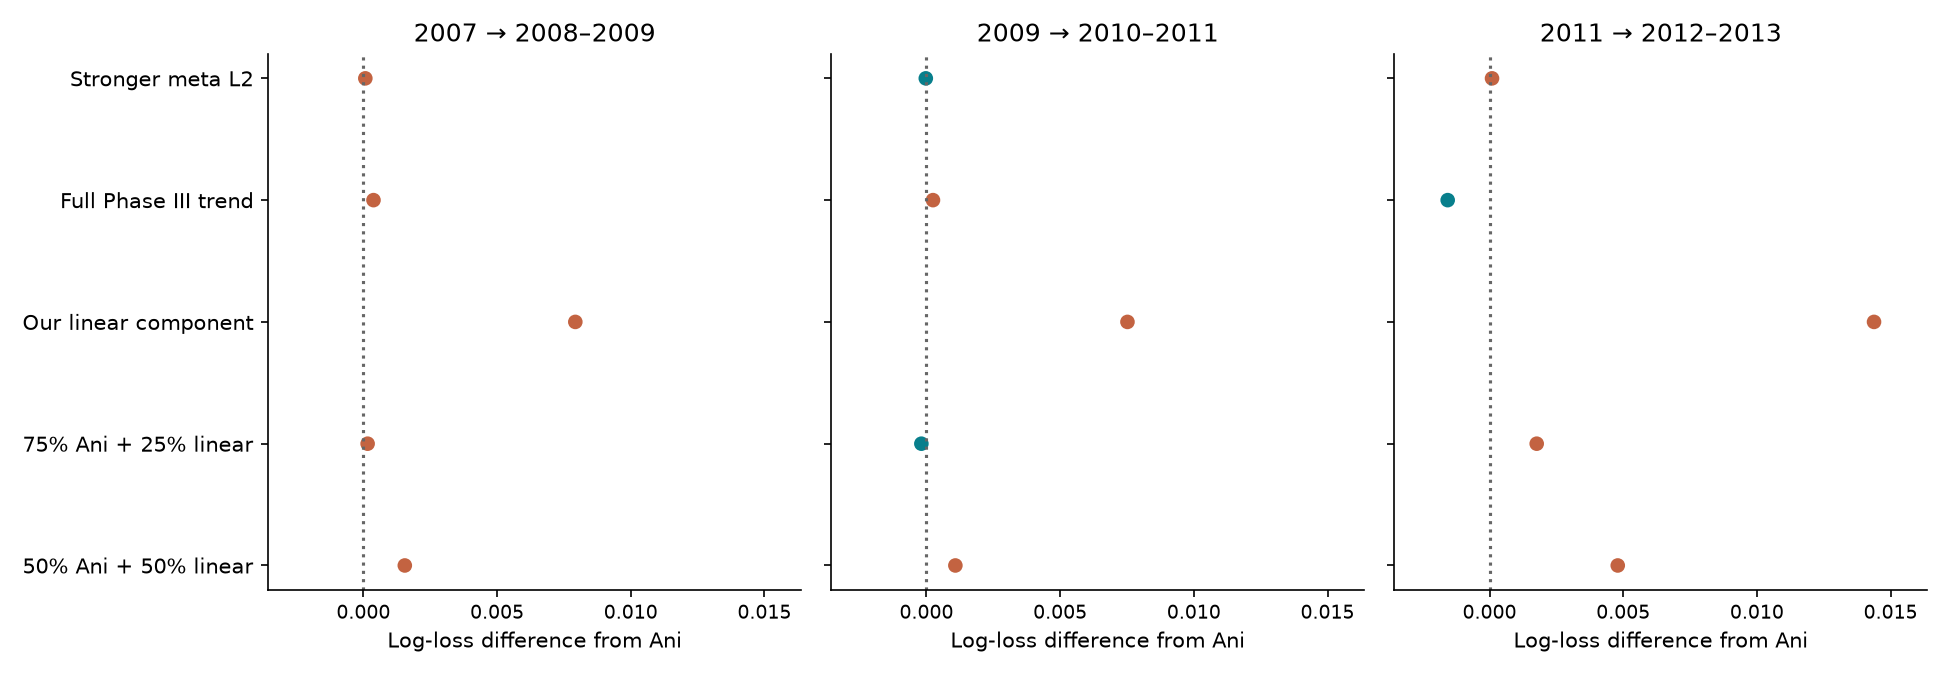

In [16]:
summary=pd.read_csv(OUT/"summary.csv")
assert summary.complete_comparison.all()
display(summary)
scores=pd.read_csv(OUT/"fold_scores.csv")
display(scores[scores.kind.eq("temporal")][["model","split","phase_mean_logloss","I_logloss","II_logloss","III_logloss"]])
display(Image(filename=str(OUT/"figures/chronological_windows.png")))


## Paired uncertainty

Intervals resample trials jointly, keeping combined-phase rows together. Repeated-CV losses are averaged per trial before resampling. Temporal intervals average the three periods equally. Negative differences favor a candidate relative to Ani. Intervals spanning zero are inconclusive.

These are descriptive, conditional intervals. They do not correct fully for model selection or represent the unseen cohort shift. The most recent temporal window has only 94 Phase I and 168 Phase III rows.


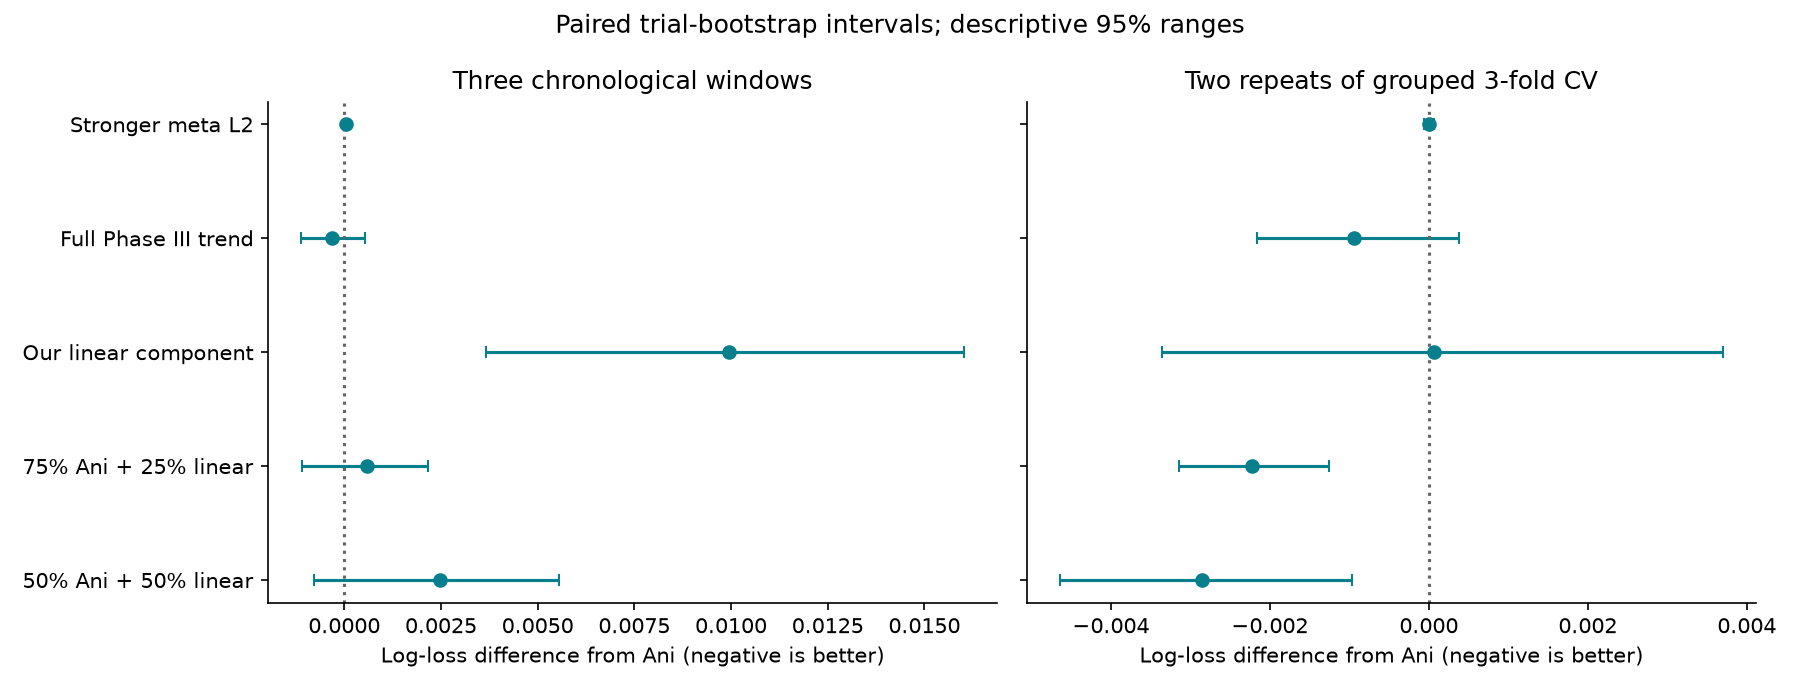

,model,temporal_delta,temporal_delta_lower,temporal_delta_upper,group_cv_delta,group_cv_delta_lower,group_cv_delta_upper
0,ani_phase3_trend,-0.000315,-0.001114,0.000523,-0.000943,-0.002160,0.000378
1,ani_stack,NaN,NaN,NaN,NaN,NaN,NaN
2,ani_meta_C0.3,0.000046,-0.000019,0.000105,-0.000001,-0.000064,0.000064
3,blend_ani75_linear25,0.000577,-0.001094,0.002156,-0.002222,-0.003147,-0.001261
4,blend_ani50_linear50,0.002475,-0.000791,0.005563,-0.002850,-0.004641,-0.000965
5,our_linear,0.009941,0.003673,0.016022,0.000060,-0.003362,0.003697


In [17]:
display(Image(filename=str(OUT/"figures/paired_comparisons.png")))
display(summary[["model","temporal_delta","temporal_delta_lower","temporal_delta_upper", "group_cv_delta","group_cv_delta_lower","group_cv_delta_upper"]])


## Faithful published-recipe track

The same labels and trial splits are used, but Ani's original feature-only transduction is preserved. Evaluation labels never fit a predictor. Compare this sensitivity track separately from the strict prospective benchmark.


In [18]:
published=pd.read_csv(OUT/"published_recipe_track/summary.csv")
assert published.complete_comparison.all()
display(published)


,model,completed_splits,expected_splits,official_logloss,temporal_windows,temporal_mean_logloss,worst_temporal_logloss,cv_completed_repeats,cv_mean_logloss,cv_repeat_std,temporal_delta,temporal_delta_lower,temporal_delta_upper,group_cv_delta,group_cv_delta_lower,group_cv_delta_upper,temporal_mean_delta_vs_ani,cv_mean_delta_vs_ani,complete_comparison
0,ani_phase3_trend,10,10,0.557150,3,0.535460,0.587985,2,0.584607,0.000291,-0.000291,-0.001077,0.000544,-0.000858,-0.002043,0.000412,-0.000291,-0.000858,True
1,ani_stack,10,10,0.556108,3,0.535751,0.587659,2,0.585465,0.000348,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,True
2,blend_ani75_linear25,10,10,0.553741,3,0.536658,0.587988,2,0.583451,0.000330,0.000907,-0.000756,0.002465,-0.002014,-0.002987,-0.001023,0.000907,-0.002014,True
3,blend_ani50_linear50,10,10,0.553374,3,0.538947,0.589581,2,0.583238,0.000868,0.003196,-0.000034,0.006239,-0.002228,-0.004111,-0.000271,0.003196,-0.002228,True
4,our_linear,10,10,0.557787,3,0.547387,0.596500,2,0.587471,0.001685,0.011636,0.005406,0.017685,0.002006,-0.001646,0.005767,0.011636,0.002006,True


## Optional conservative candidates

07 stays anchored to the winning published file and puts 25% weight on Ani's existing capped Phase III year-trend alternative. 08 blends 75% of that winning file with 25% of our linear component, now refitted on the same 9,050 labeled rows as Ani's final fit. Both were evaluated using matching component predictions on every saved split in both tracks. They are exploratory candidates with unknown Kaggle scores, not established improvements.

05 remains on hold because the new time-based comparisons favor Ani over our linear endpoint. Preserve the 0.58688 file until a new submitted score actually improves it. Full source recipes and hashes are in `submissions/ani_candidates_manifest.json`.


In [19]:
for track in [OUT,OUT/"published_recipe_track"]:
    display(pd.read_csv(track/"derived_candidates/summary.csv"))
display(pd.read_csv(ROOT/"submissions/ani_candidates_index.csv"))
display(json.loads((ROOT/"submissions/ani_candidates_manifest.json").read_text()))


,model,completed_splits,expected_splits,official_logloss,temporal_windows,temporal_mean_logloss,worst_temporal_logloss,cv_completed_repeats,cv_mean_logloss,cv_repeat_std,temporal_delta,temporal_delta_lower,temporal_delta_upper,group_cv_delta,group_cv_delta_lower,group_cv_delta_upper,temporal_mean_delta_vs_ani,cv_mean_delta_vs_ani,complete_comparison
0,ani_mild_phase3_trend,10,10,0.555034,3,0.537306,0.588557,2,0.586776,0.000573,-0.000140,-0.000337,0.000067,-0.000635,-0.000953,-0.000308,-0.000140,-0.000635,True
1,ani_stack,10,10,0.555039,3,0.537446,0.588574,2,0.587411,0.000591,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,True
2,ani_anchored_linear25,10,10,0.553327,3,0.538022,0.588732,2,0.585189,0.000127,0.000577,-0.001094,0.002156,-0.002222,-0.003147,-0.001261,0.000577,-0.002222,True


,model,completed_splits,expected_splits,official_logloss,temporal_windows,temporal_mean_logloss,worst_temporal_logloss,cv_completed_repeats,cv_mean_logloss,cv_repeat_std,temporal_delta,temporal_delta_lower,temporal_delta_upper,group_cv_delta,group_cv_delta_lower,group_cv_delta_upper,temporal_mean_delta_vs_ani,cv_mean_delta_vs_ani,complete_comparison
0,ani_mild_phase3_trend,10,10,0.556118,3,0.535617,0.587627,2,0.584866,0.000335,-0.000134,-0.000328,0.000072,-0.000599,-0.000905,-0.000282,-0.000134,-0.000599,True
1,ani_stack,10,10,0.556108,3,0.535751,0.587659,2,0.585465,0.000348,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,True
2,ani_anchored_linear25,10,10,0.553741,3,0.536658,0.587988,2,0.583451,0.000330,0.000907,-0.000756,0.002465,-0.002014,-0.002987,-0.001023,0.000907,-0.002014,True


,submission,mean_test_probability,mean_abs_change_from_ani,sha256,kaggle_score
0,07_ani_mild_phase3_trend.csv,0.634970,0.004530,4ef1f2087aba2fd33f89d1bd870dd06dd492bf2a65e358...,NaN
1,08_ani_linear25.csv,0.629038,0.012797,8f254268cac73620a94917cf390df74c334db2d67a168b...,NaN


{'baseline_score': 0.58688,
 'baseline_source_commit': '1b8bd11c47428fb5453e53cdc275542b92a3b347',
 'reference_file_sha256': '17caa6b02af919c8ba6358d680075208ba8d4f1d11c20d5b6d06e8f6d494b3c2',
 'trend_file_sha256': '79bc34c128e6be1e34feb8ac4e0694ac899b0c4f52b8886d15becbc7a094248e',
 'benchmark_run': 'experiments/local_benchmark/runs/68db59271f5f0b9d',
 'linear_final_training_rows': 9050,
 'recipe': {'07_ani_mild_phase3_trend': {'Ani 0.58688 published probabilities': 0.75,
   'Ani capped Phase III trend alternative': 0.25},
  '08_ani_linear25': {'Ani 0.58688 published probabilities': 0.75,
   'Our linear component refitted on train+validation': 0.25}},
 'files': [{'submission': '07_ani_mild_phase3_trend.csv',
   'mean_test_probability': 0.6349695393142645,
   'mean_abs_change_from_ani': 0.004530087478559439,
   'sha256': '4ef1f2087aba2fd33f89d1bd870dd06dd492bf2a65e35848d4bbbfe8aeeecc9e',
   'kaggle_score': None},
  {'submission': '08_ani_linear25.csv',
   'mean_test_probability': 0.6290

## Repeatability checks and commands

The protocol tests check trial separation, test-set exclusion, repeated-CV coverage, chronological ordering, equal-phase loss, a known paired-bootstrap result and incomplete-run handling. Run the commands from the repository root:

```sh
make -C AML-Midterm/part2 benchmark-test
make -C AML-Midterm/part2 benchmark
make -C AML-Midterm/part2 benchmark-report
```

New code or package versions receive a separate result fingerprint. Dataset changes are rejected by the existing protocol. Final fitting and held-out benchmark scores remain separate. See `LOCAL_TESTING.md` for the full operating procedure and limitations.


In [20]:
from benchmark_protocol import resolve
for split in protocol["splits"]:
    train,ev=resolve(universe,split)
    assert not set(train.trial_id)&set(ev.trial_id)
for path in (OUT/"models").glob("*/audit.json"):
    audit=json.loads(path.read_text())
    assert audit["trial_overlap"]==0
    assert all(f["trial_overlap"]==0 for f in audit["inner_folds"])
sample=pd.read_csv(ROOT/"part2_sample_submission.csv")
for row in pd.read_csv(ROOT/"submissions/ani_candidates_index.csv").itertuples():
    result=pd.read_csv(ROOT/"submissions"/row.submission)
    assert len(result)==1500 and result.ID.is_unique and result.ID.equals(sample.ID)
    assert result.label.between(0,1,inclusive="neither").all()
print("All ten split audits and both candidate CSVs pass.")
verification=ROOT/"experiments/local_benchmark/verification.json"
if verification.exists():display(json.loads(verification.read_text()))


All ten split audits and both candidate CSVs pass.


{'splits': 10,
 'strict_recipes': 6,
 'published_recipe_variants': 5,
 'complete_comparisons': True,
 'dataset_and_source_hashes_match': True,
 'native_probability_replay_max_errors': {'ani_stack': 5.551115123125783e-16,
  'our_linear': 5.551115123125783e-16},
 'valid_submission_files': 8,
 'cached_run_refits_no_models': True,
 'cached_metrics_and_intervals_repeat': True}